# Selekcja zmiennych za pomocą Random Forest

Zadanie z `RF_Var_Select.pptx` na bazie `VLagun_PhysChem_Years4.csv`.

## 1. Wczytanie danych, liczba zmiennych i zmienna `y`

In [1]:
import pandas as pd

data = pd.read_csv('../zadania/VLagun_PhysChem_Years4.csv')
X = data.iloc[:, 0:19]
y = data.iloc[:, 19]
features_names = data.columns
data.head()

,PSU,O2,temp.,SS,SRP,DOP,PP,NH4N,NO3N,DON,PN,TN/TP,Fe,SiO4Si,DOC,TPOC,Windspeedinsitu,Depth,DINtoDIP,Years
0,3.757624,9.46,18.3,52.0,3.5,11.7,185.0,0.039,0.022,0.551,0.759,6.848152,0.0121,2.3112,7.500,8.5650,3.5,3.3,17.428571,0
1,3.504707,9.89,19.1,50.0,4.4,17.5,111.3,0.020,0.025,0.123,1.181,10.127628,0.0136,2.1157,7.860,8.5200,0.0,3.6,10.227273,0
2,3.757624,9.66,18.1,59.0,3.2,22.8,103.4,0.016,0.008,0.582,0.576,9.134467,0.0368,2.2641,8.172,8.4915,1.0,3.4,7.500000,0
3,3.107266,10.36,19.5,46.0,4.3,22.3,92.7,0.026,0.021,0.693,0.689,11.978206,0.0172,2.2623,7.848,8.8320,0.0,2.9,10.930233,0
4,2.619498,11.56,19.0,42.0,11.7,30.3,73.2,0.022,0.048,0.383,1.006,12.664931,0.0237,2.2164,7.536,9.2400,0.0,3.0,5.982906,0


In [2]:
print('Features Shape:', data.shape)
print('Liczba zmiennych (kolumn):', data.shape[1])
print('Liczba obserwacji (wierszy):', data.shape[0])
print('Liczba cech w X:', X.shape[1])
print('Nazwy cech:', list(X.columns))
print('Zmienna y:', features_names[19], '| unikalne wartości:', sorted(y.unique()))
print('y dtype:', y.dtype)
y.head()

Features Shape: (120, 20)
Liczba zmiennych (kolumn): 20
Liczba obserwacji (wierszy): 120
Liczba cech w X: 19
Nazwy cech: ['PSU', 'O2', 'temp.', 'SS', 'SRP', 'DOP', 'PP', 'NH4N', 'NO3N', 'DON', 'PN', 'TN/TP', 'Fe', 'SiO4Si', 'DOC', 'TPOC', 'Windspeedinsitu', 'Depth', 'DINtoDIP']
Zmienna y: Years | unikalne wartości: [np.int64(0), np.int64(1)]
y dtype: int64


0    0
1    0
2    0
3    0
4    0
Name: Years, dtype: int64

## 2. Model RF + lista ważności zmiennych (posortowana)

In [3]:
from sklearn.ensemble import RandomForestRegressor
import numpy as np

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X, y)

importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

for i in indices:
    print(X.columns[i], importances[i])

Windspeedinsitu 0.3691279556268485
DOC 0.21533693442451995
SS 0.08060777055841534
temp. 0.07790081454922056
SiO4Si 0.06806378115215292
TPOC 0.03414537362623922
PSU 0.03190507394162355
DINtoDIP 0.01543386445091692
PN 0.014872554391167641
PP 0.014702188288849297
TN/TP 0.014456222928889026
DOP 0.013983324598623103
Fe 0.011077016096328418
NO3N 0.008764932070171663
Depth 0.008510685985174741
DON 0.007685484481212123
NH4N 0.005806634578773869
SRP 0.004036798831773258
O2 0.003582589419099777


In [4]:
importances = list(rf.feature_importances_)

# List of tuples with variable and importance
feature_importances = [(feature, round(importance, 3))
                       for feature, importance in zip(X.columns, importances)]

# Sort the feature importances by most important first
feature_importances = sorted(feature_importances, key=lambda x: x[1], reverse=True)

# Print out the feature and importances
[print('Variable: {:31} Importance: {}'.format(*pair)) for pair in feature_importances];

Variable: Windspeedinsitu                 Importance: 0.369
Variable: DOC                             Importance: 0.215
Variable: SS                              Importance: 0.081
Variable: temp.                           Importance: 0.078
Variable: SiO4Si                          Importance: 0.068
Variable: TPOC                            Importance: 0.034
Variable: PSU                             Importance: 0.032
Variable: PP                              Importance: 0.015
Variable: PN                              Importance: 0.015
Variable: DINtoDIP                        Importance: 0.015
Variable: DOP                             Importance: 0.014
Variable: TN/TP                           Importance: 0.014
Variable: Fe                              Importance: 0.011
Variable: NO3N                            Importance: 0.009
Variable: Depth                           Importance: 0.009
Variable: DON                             Importance: 0.008
Variable: NH4N                          

## 3. Estymator RF + wizualizacja posortowanych ważności

In [5]:
%matplotlib inline
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import model_selection
from sklearn import preprocessing
from sklearn import ensemble, tree, metrics

In [6]:
estimator_rf = ensemble.RandomForestRegressor(
    n_jobs=-1,
    n_estimators=100,
    random_state=42)

estimator_rf.fit(X, y)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [7]:
feature_importance_df = pd.DataFrame(
    estimator_rf.feature_importances_,
    index=X.columns.values,
    columns=['Importance']
)
feature_importance_df.head()

,Importance
PSU,0.031905
O2,0.003583
temp.,0.077901
SS,0.080608
SRP,0.004037


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5892\2156103119.py:1: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  feature_importance_df.sort_values(by='Importance', inplace=True, ascending=False)


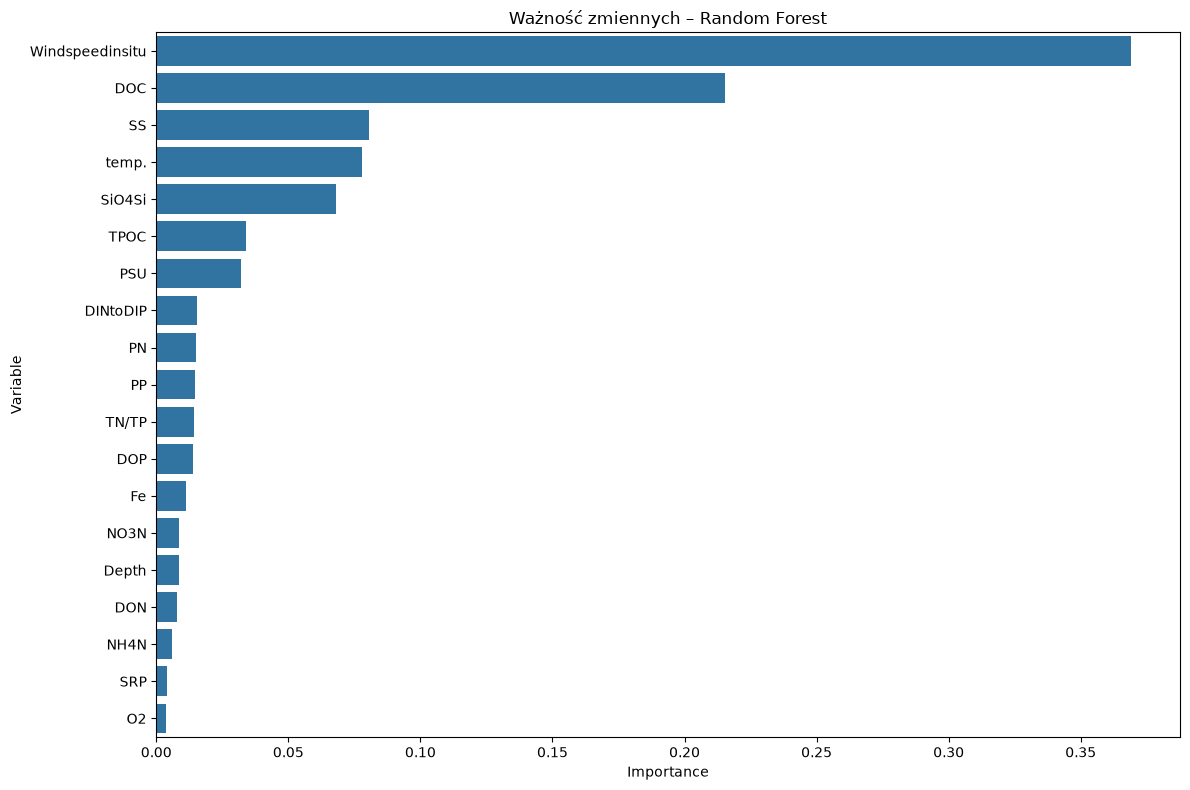

,Importance
Windspeedinsitu,0.369128
DOC,0.215337
SS,0.080608
temp.,0.077901
SiO4Si,0.068064
TPOC,0.034145
PSU,0.031905
DINtoDIP,0.015434
PN,0.014873
PP,0.014702


In [8]:
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=feature_importance_df,
    x=feature_importance_df.values.flatten(),
    y=feature_importance_df.index.values
)
plt.xlabel('Importance')
plt.ylabel('Variable')
plt.title('Ważność zmiennych – Random Forest')
plt.tight_layout()
plt.show()

feature_importance_df